# Последний эксперимент: высокие частоты

Сравниваем два режима на k ∈ [4,8]: (1) frozen модели, обученные на k ∈ [1,2], и (2) отдельное обучение всех трёх методов на новой полосе. Геометрия, DG0-среды и split IDs совпадают; test-частоты не участвуют ни в одном обучении. Высокочастотные решения вычисляем заново FEM-решателем. Это frequency shift, а не одновременная смена материалов/геометрии.

POD для второго режима строится заново только по high-band train. Для первого режима базисы и нормализация заморожены. Дополнительно проверяем h → h/2 на трёх test-частотах с максимальным k; число точек на длину волны само по себе не доказывает FEM-сходимость.

**Статичная задача:** геометрия и исходная среда №0 фиксированы; A,n и DG0-материалы одинаковы во всех примерах. Меняются k и θ. Один medium_id=0, разбиение по frequency_id: 670/170/160 частот (5360/1360/1280 полей). 1000 частот × 8 направлений = 8000 полей на полосу. Этот эксперимент проверяет интерполяцию параметров волны на одной среде.

**Профиль:** выберите `POD_METHOD="full"` или `"randomized"` в первой ячейке. Данные общие; пути результатов разделены. Сохранённые outputs относятся к randomized. Это выбор алгоритма POD, а не отдельные версии Chebyshev/FNO.


In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'neural_operator').is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from neural_operator import settings as full_settings
from neural_operator.randomized import settings as randomized_settings
POD_METHOD = "randomized"  # "full" uses separate runs; saved outputs below are randomized.
if POD_METHOD not in {"full", "randomized"}:
    raise ValueError("POD_METHOD must be full or randomized")
settings = randomized_settings if POD_METHOD == "randomized" else full_settings
BASE, N_FREQUENCIES, N_DIRECTIONS, DATASET_TAG = (settings.BASE, settings.N_FREQUENCIES,
    settings.N_DIRECTIONS, settings.DATASET_TAG)
LOW_DATA_DIR, HIGH_DATA_DIR = settings.LOW_DATA_DIR, settings.HIGH_DATA_DIR
LOW_RUNS, HIGH_RUNS = settings.LOW_RUNS, settings.HIGH_RUNS
SVD_RUNS, COMPARISON_RUNS = settings.SVD_RUNS, settings.COMPARISON_RUNS
DATA_DIR = LOW_DATA_DIR
RUNS = LOW_RUNS
import json
import numpy as np
import matplotlib.pyplot as plt
from neural_operator.datasets import load_dataset, write_dataset_info
from neural_operator.plotting import display_table, plot_prediction, plot_history


In [2]:
from dataclasses import replace
from neural_operator.datasets import StaticDatasetConfig, generate_dataset
from neural_operator.training import TrainConfig, run_experiment
from neural_operator.experiments import evaluate_frequency_shift, refinement_study
config_values = json.loads((DATA_DIR / 'config.json').read_text())
config_values.pop('medium_mode')
low_config = StaticDatasetConfig(**config_values)
high_config = replace(low_config, k_range=(4., 8.))
HIGH_DATA = HIGH_DATA_DIR
high = generate_dataset(HIGH_DATA, high_config)
high_info = write_dataset_info(high)
low_info = json.loads((DATA_DIR / 'dataset_info.json').read_text())
# Compare persisted array hashes without holding both large datasets in RAM.
for field in ['coordinates', 'triangles', 'cell_tags', 'A_cells', 'n_cells', 'theta', 'medium_id', 'frequency_id', 'split']:
    if high_info['field_sha256'][field] != low_info['field_sha256'][field]:
        raise ValueError(f'Low/high datasets differ in {field}')
print('High-band data:', high.u_scat.shape, 'k:', (high.k0.min(), high.k0.max()))


High-band data: (8000, 3221) k: (np.float64(4.0), np.float64(8.0))


In [3]:
# This notebook preserves the saved legacy v1 comparison; v2 needs separate run paths.
RETRAIN = False
METHODS = ['svd']  # Add chebyshev/fno after their low-band training finishes.
for method in METHODS:
    config = TrainConfig(method=method, epochs=200, width=24, depth=3,
                         rank=48, input_rank=32, sno_architecture_version=1, resolution=32, modes=8, seed=42, threads=2, pod_method=POD_METHOD)
    _, metrics, _ = run_experiment(high, HIGH_RUNS / method, config, retrain=RETRAIN)
    print(method, metrics['test_fem_l2'])


Loaded completed local svd run: /workspace/multiscale-fem-scattering/neural_operator/randomized/runs/high_frequency_static_1000x8/svd


svd {'mean': 0.05537525831383929, 'median': 0.0506831967266671, 'p95': 0.09035695414735936, 'max': 0.17859506890449298}


In [4]:
OUT = HIGH_RUNS / 'comparison'
low_dirs = {m: RUNS / m for m in METHODS}
high_dirs = {m: HIGH_RUNS / m for m in METHODS}
rows, summaries, resolution = evaluate_frequency_shift(low_dirs, high, OUT, high_dirs)
display_table(summaries)
display_table(resolution)


method,mean,median,p95,max,samples,media,groups,split_strategy,batch_seconds_per_sample,single_seconds_median,preprocessing_seconds,training_seconds,parameters,regime,pod_projection_mean
SVD-SNO,1.4418,1.4309,1.5496,1.7408,1280,1,160,frequency,0.00013609,0.00058846,25.503,74.216,3110,frozen_low_band,0.96771
SVD-SNO,0.055375,0.050683,0.090357,0.1786,1280,1,160,frequency,0.00030624,0.00090133,26.523,161.44,13370,retrained_high_band,0.01269


sample_index,k,h_max,h_median,k_local_max,kh_max,points_per_wavelength_min,resolution_estimate
8,4.004,0.13786,0.087065,7.7482,0.55197,11.383,cellwise DG0
32,4.016,0.13786,0.087065,7.7714,0.55363,11.349,cellwise DG0
48,4.024,0.13786,0.087065,7.7869,0.55473,11.326,cellwise DG0
184,4.0921,0.13786,0.087065,7.9187,0.56412,11.138,cellwise DG0
296,4.1481,0.13786,0.087065,8.0271,0.57185,10.988,cellwise DG0
312,4.1562,0.13786,0.087065,8.0426,0.57295,10.966,cellwise DG0
392,4.1962,0.13786,0.087065,8.1201,0.57847,10.862,cellwise DG0
552,4.2763,0.13786,0.087065,8.2751,0.58951,10.658,cellwise DG0
568,4.2843,0.13786,0.087065,8.2906,0.59061,10.638,cellwise DG0
576,4.2883,0.13786,0.087065,8.2983,0.59116,10.628,cellwise DG0


In [5]:
refinement = refinement_study(high, OUT, n_groups=3)
display_table(refinement)


Info    : Reading '/workspace/multiscale-fem-scattering/neural_operator/data/static_high_frequency_1000x8/etal.msh'...
Info    : 175 entities
Info    : 3221 nodes
Info    : 6440 elements
Info    : Done reading '/workspace/multiscale-fem-scattering/neural_operator/data/static_high_frequency_1000x8/etal.msh'


Info    : Reading '/tmp/tmp4tkiyqgw/refined.msh'...
Info    : 175 entities
Info    : 8958 nodes
Info    : 17914 elements
Info    : Done reading '/tmp/tmp4tkiyqgw/refined.msh'


Info    : Reading '/workspace/multiscale-fem-scattering/neural_operator/data/static_high_frequency_1000x8/etal.msh'...
Info    : 175 entities
Info    : 3221 nodes
Info    : 6440 elements
Info    : Done reading '/workspace/multiscale-fem-scattering/neural_operator/data/static_high_frequency_1000x8/etal.msh'


Info    : Reading '/tmp/tmpb715b7zx/refined.msh'...
Info    : 175 entities
Info    : 8958 nodes
Info    : 17914 elements
Info    : Done reading '/tmp/tmpb715b7zx/refined.msh'


Info    : Reading '/workspace/multiscale-fem-scattering/neural_operator/data/static_high_frequency_1000x8/etal.msh'...
Info    : 175 entities
Info    : 3221 nodes
Info    : 6440 elements
Info    : Done reading '/workspace/multiscale-fem-scattering/neural_operator/data/static_high_frequency_1000x8/etal.msh'


Info    : Reading '/tmp/tmphqzn_jqy/refined.msh'...
Info    : 175 entities
Info    : 8958 nodes
Info    : 17914 elements
Info    : Done reading '/tmp/tmphqzn_jqy/refined.msh'


sample_index,k,method,error_fem_l2,dofs_original,dofs_refined,refined_h,refined_solve_seconds
7904,7.956,Fine FEM vs refined FEM,0.13656,3221,8958,0.05,0.43562
7888,7.9479,Fine FEM vs refined FEM,0.13594,3221,8958,0.05,0.30092
7784,7.8959,Fine FEM vs refined FEM,0.13322,3221,8958,0.05,0.29597


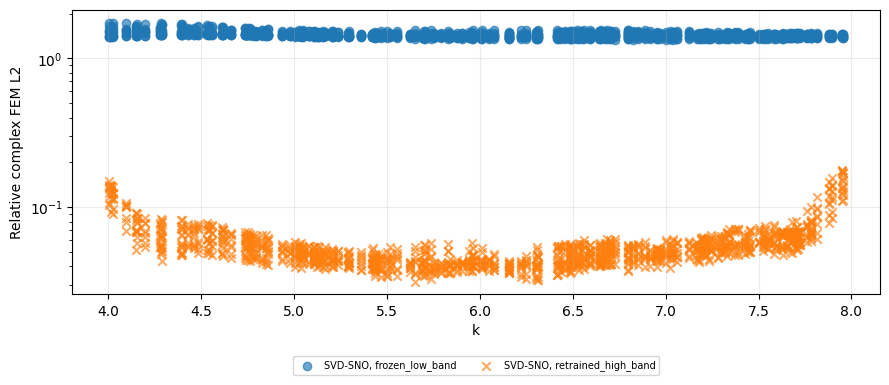

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
for regime, marker in [('frozen_low_band', 'o'), ('retrained_high_band', 'x')]:
    for method in sorted({row['method'] for row in rows}):
        selected = [r for r in rows if r['regime'] == regime and r['method'] == method]
        ax.scatter([r['k'] for r in selected], [r['error_fem_l2'] for r in selected],
                   marker=marker, alpha=.65, label=f'{method}, {regime}')
ax.set(yscale='log', xlabel='k', ylabel='Relative complex FEM L2')
ax.legend(fontsize=7, ncol=2, loc='upper center', bbox_to_anchor=(.5, -.20))
ax.grid(alpha=.25)
fig.tight_layout(); fig.savefig(OUT / 'frequency_errors.png', dpi=160)
plt.show()


Интерпретация: frozen error содержит frequency extrapolation и для SVD — ошибку переноса замороженного базиса. Retrained error проверяет другую обученную полосу при том же небольшом budget. Ошибка относительно fine FEM не учитывает всю ошибку FEM относительно непрерывной PDE; для неё отдельно смотрите refinement. Если rank/modes cap недостаточен, увеличение числа эпох не устраняет ограничение представления. Одна seed-серия на 1000 частотах — пилотное исследование, не доказательство высокочастотной точности.
